         Date    Product  Sales  Quantity Region
0  2023-01-01  Product A    200         4  North
1  2023-01-02  Product B    150         3  South
2  2023-01-03  Product A    220         5  North
3  2023-01-04  Product C    300         6   East
4  2023-01-05  Product B    180         4   West
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64
            Sales   Quantity
count   16.000000  16.000000
mean   233.750000   5.187500
std     65.612499   1.721191
min    150.000000   3.000000
25%    180.000000   4.000000
50%    215.000000   5.000000
75%    302.500000   6.250000
max    340.000000   8.000000
     Product  Sales  Quantity
0  Product A   1290        30
1  Product B    850        17
2  Product C   1600        36


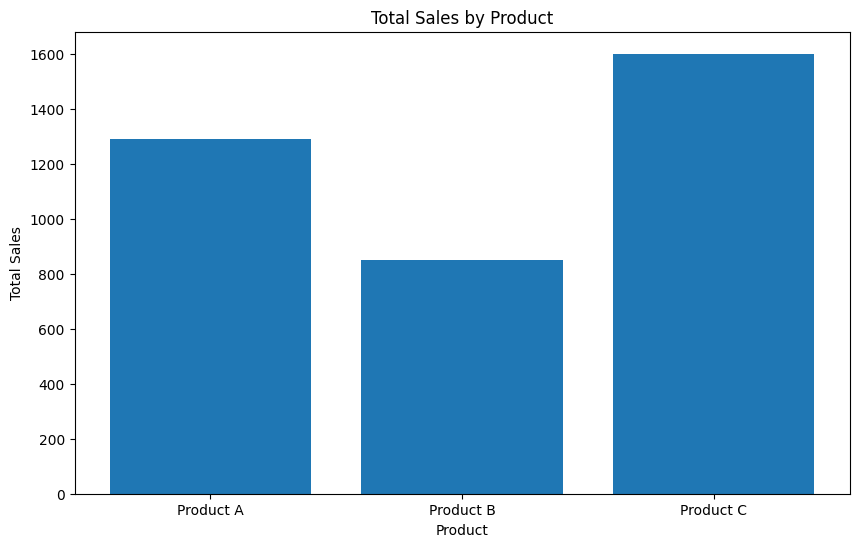

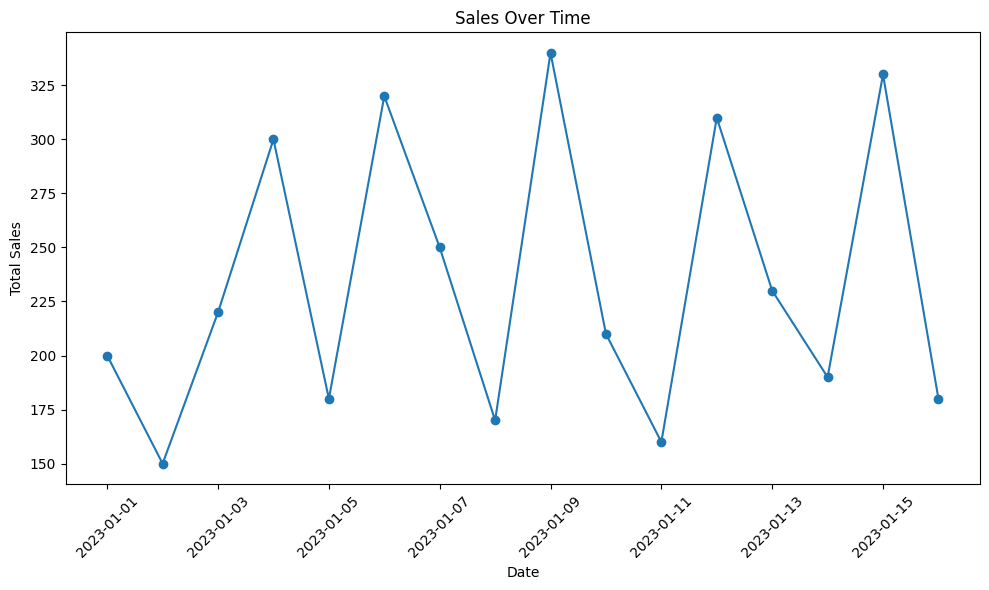

Product  Product A  Product B  Product C
Region                                  
East           210        190        620
North          670        160        330
South          180        320        310
West           230        180        340
             Sales  Quantity
Sales     1.000000  0.949689
Quantity  0.949689  1.000000


/tmp/ipykernel_1317/70267999.py:55: FutureWarning: The provided callable <function sum at 0x7e906539c7c0> is currently using DataFrameGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  pivot_table = df.pivot_table(


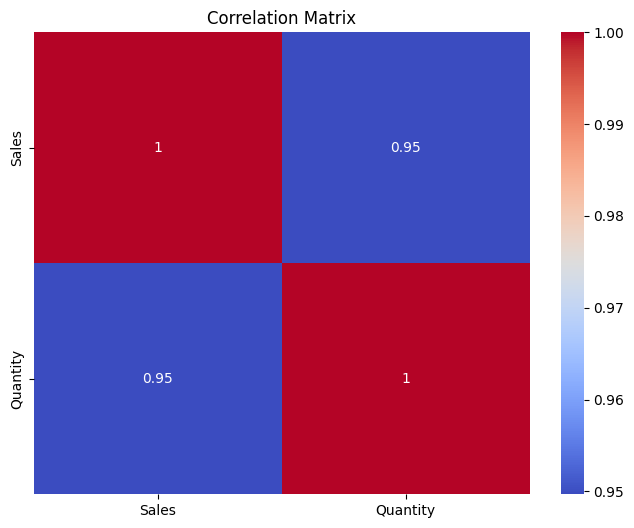

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/sales_data.csv'
df = pd.read_csv(file_path)

print(df.head())

print(df.isnull().sum())

df['Sales'] = df['Sales'].fillna(df['Sales'].mean())

df.dropna(subset=['Product', 'Quantity', 'Region'], inplace=True)

print(df.describe())

product_summary = df.groupby('Product').agg({
    'Sales': 'sum',
    'Quantity': 'sum'
}).reset_index()

print(product_summary)

plt.figure(figsize=(10, 6))
plt.bar(product_summary['Product'], product_summary['Sales'])
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.title('Total Sales by Product')
plt.show()

df['Date'] = pd.to_datetime(df['Date'])

sales_over_time = df.groupby('Date').agg({
    'Sales': 'sum'
}).reset_index()

plt.figure(figsize=(10, 6))
plt.plot(sales_over_time['Date'], sales_over_time['Sales'], marker='o')
plt.xlabel('Date')
plt.ylabel('Total Sales')
plt.title('Sales Over Time')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

pivot_table = df.pivot_table(
    values='Sales',
    index='Region',
    columns='Product',
    aggfunc=np.sum,
    fill_value=0
)

print(pivot_table)
correlation_matrix = df.corr(numeric_only=True)
print(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()
